<a href="https://colab.research.google.com/github/savneetbadial/Wide-Receiver-Stats-Model/blob/main/TPU_Wide_Receiver_Stats_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Define your file path in Google Drive
# Adjust the folder path if you put it somewhere else
file_path = '/content/drive/My Drive/Colab Notebooks/NFL/wr_games_raw.csv'

# Load the dataset directly
df = pd.read_csv(file_path)
print(f"Successfully loaded {len(df):,} rows from Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully loaded 27,962 rows from Google Drive!


In [14]:
!pip install tensorflow

In [15]:
import tensorflow as tf

# Initialize TPU for single-core v5e-1 TPU runtime in Colab
try:
    resolver = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(resolver)
    tf.tpu.experimental.initialize_tpu_system(resolver)
    strategy = tf.distribute.TPUStrategy(resolver)
    print("Successfully connected to TPU v5e-1:", resolver.master())
except Exception as e:
    print(f"TPU initialization note: {e}")
    # Fallback for single-core Colab TPU runtimes
    try:
        import jax
        print("JAX TPU devices:", jax.devices())
    except:
        pass
    strategy = tf.distribute.get_strategy()

print(f"Replicas in sync: {strategy.num_replicas_in_sync}")

TPU initialization note: Please provide a TPU Name to connect to.
JAX TPU devices: [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)]
Replicas in sync: 1


Initializing TensorFlow backend for TPU...
-> TPU strategy setup note: Please provide a TPU Name to connect to.
Loading raw dataset from /content/drive/MyDrive/Colab Notebooks/NFL/wr_games_raw2.csv...
Dataset split sizes -> Train (<=2023): 24,803, Val (2024): 1,697, Test (2025): 1,462


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_receiving_yards (Dense)  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,801 (175.00 KB)

 Trainable params: 44,801 (175.00 KB)

 Non-trainable params: 0 (0.00 B)


Starting TPU Training via TensorFlow Backend...
Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1646.2028 - mae: 29.2428 - val_loss: 1045.2092 - val_mae: 24.2289
Epoch 2/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1131.1099 - mae: 25.2480 - val_loss: 1019.8680 - val_mae: 23.6914
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1109.4683 - mae: 24.9588 - val_loss: 1002.2175 - val_mae: 23.2519
Epoch 4/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1096.4783 - mae: 24.8051 - val_loss: 1003.1224 - val_mae: 23.6136
Epoch 5/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1093.0081 - mae: 24.7848 - val_loss: 993.8003 - val_mae: 23.2367
Epoch 6/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1092.5754 - mae: 24.7595 - val_loss: 983.3911 - val_mae: 23.1399
Epoch 7/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1087.5475 - mae: 24.7060 - val_loss: 986.4221 - val_mae: 23.2869
Epoch 8/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1086.5864 - mae: 24.6894 - v

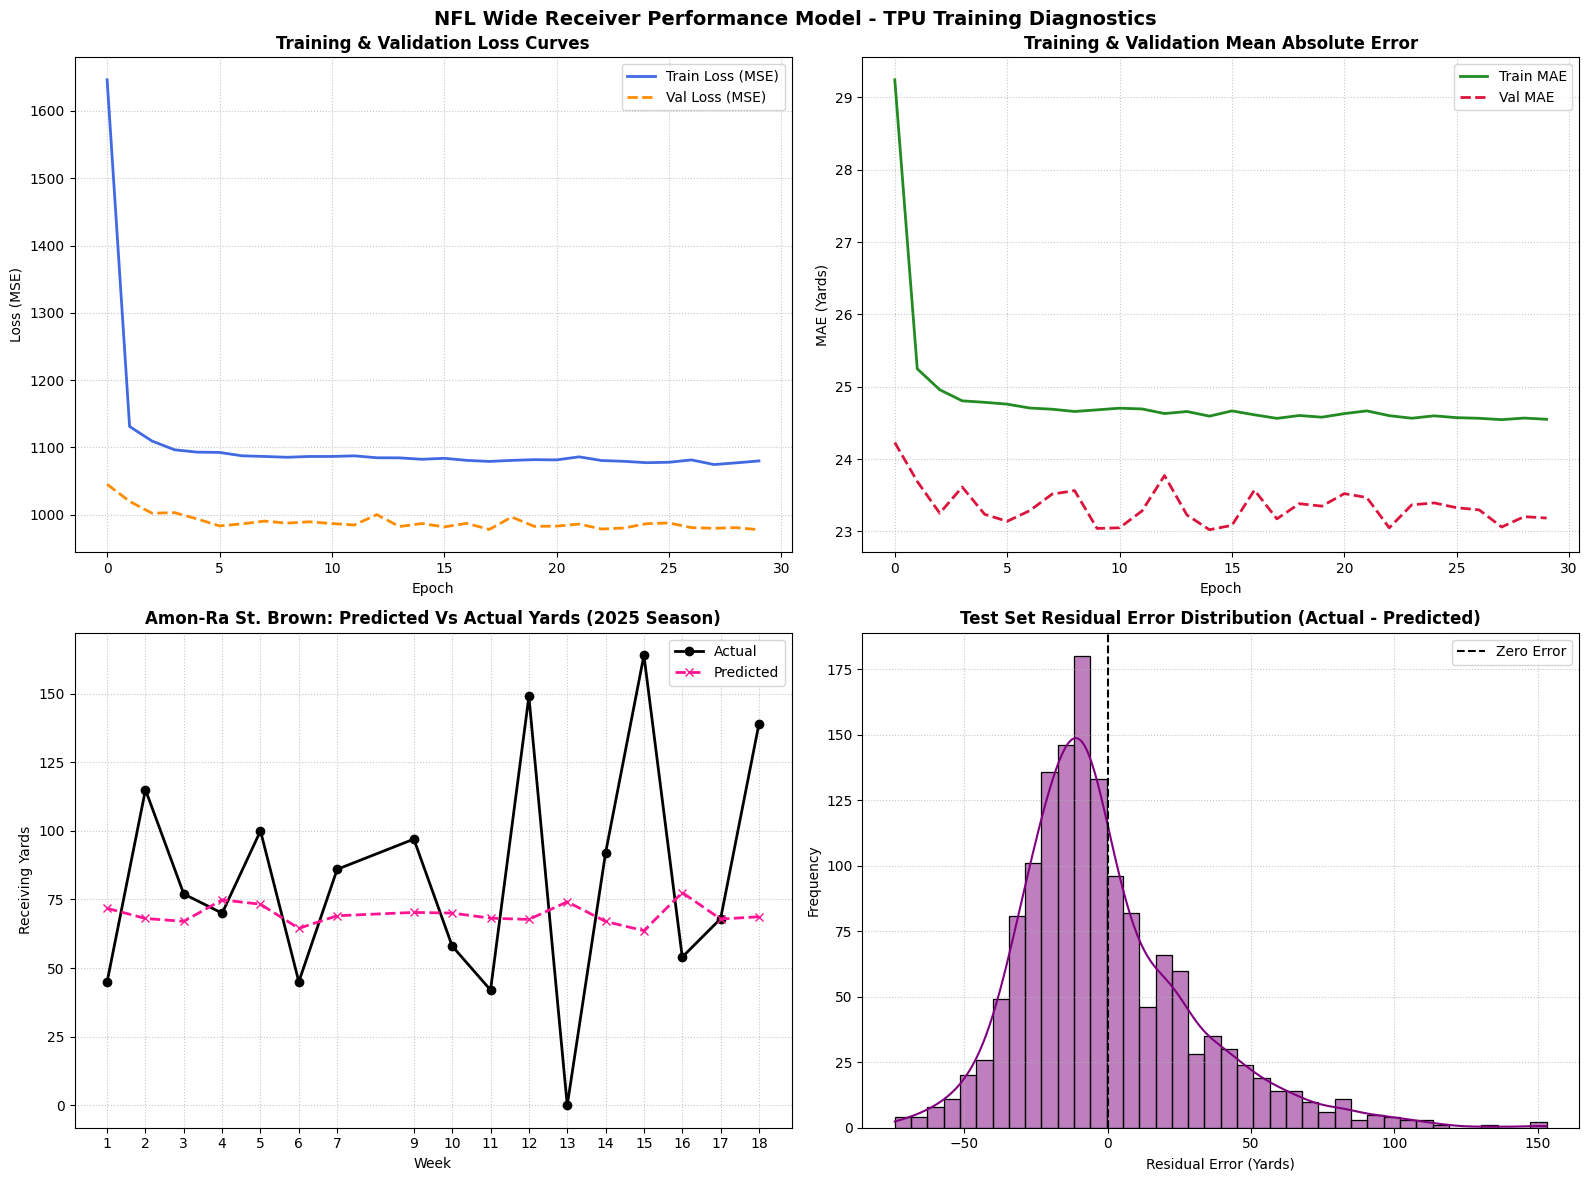

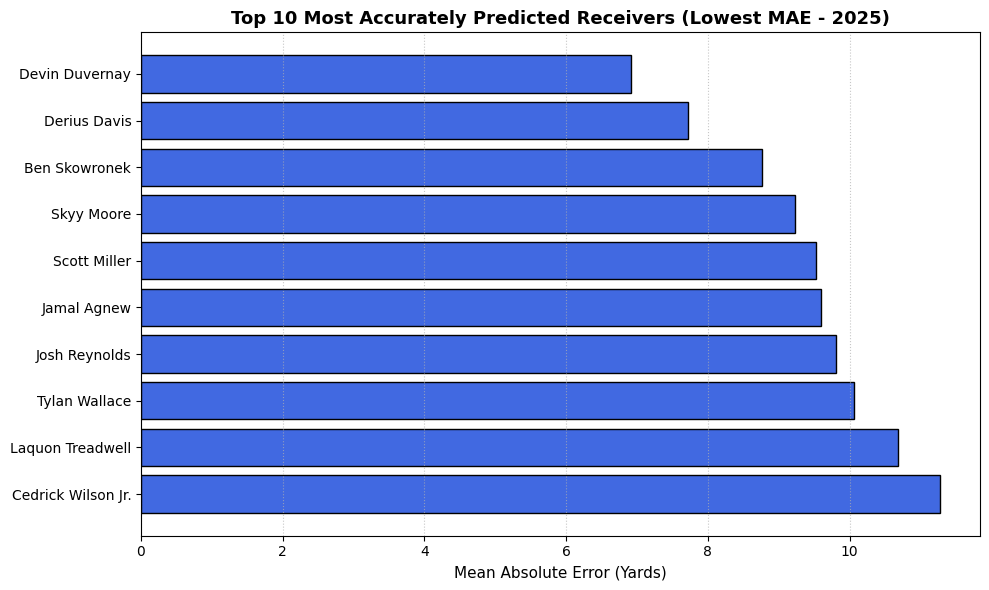

In [30]:
# 1. ENVIRONMENT & BACKEND SETUP
import sys
import os

import site
import importlib
importlib.reload(site)

os.environ["KERAS_BACKEND"] = "tensorflow"

import time
import psutil
import keras
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Initializing TensorFlow backend for TPU...")
try:
    resolver = tf.distribute.cluster_resolver.TPUClusterResolver()
    strategy = tf.distribute.TPUStrategy(resolver)
    print("-> TPU Strategy configured with TensorFlow backend.")
except Exception as e:
    print(f"-> TPU strategy setup note: {e}")
    strategy = tf.distribute.get_strategy()

# 2. DATA INGESTION & PREPARATION
csv_file_path = '/content/drive/MyDrive/Colab Notebooks/NFL/wr_games_raw2.csv'
print(f"Loading raw dataset from {csv_file_path}...")
df = pd.read_csv(csv_file_path)

features = [
    'home', 'targets_avg3', 'rec_avg3', 'yds_avg3', 'td_avg3',
    'targets_avg8', 'rec_avg8', 'yds_avg8', 'yac_avg8',
    'team_pass_att_avg3', 'opp_wr_yds_allowed_avg5', 'opp_pass_def_rank',
    'games_played_career'
]
target = 'receiving_yards'

# Seasonal out-of-time splitting logic
train_years = df[df['season'] <= 2023]
val_years   = df[df['season'] == 2024]
test_years  = df[df['season'] == 2025]

X_train = train_years[features].fillna(0).values
X_val   = val_years[features].fillna(0).values
X_test  = test_years[features].fillna(0).values

y_train = train_years[target].values.astype('float32')
y_val   = val_years[target].values.astype('float32')
y_test  = test_years[target].values.astype('float32')

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_val   = scaler.transform(X_val).astype('float32')
X_test  = scaler.transform(X_test).astype('float32')

BATCH_SIZE = 256

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Dataset split sizes -> Train (<=2023): {len(X_train):,}, Val (2024): {len(X_val):,}, Test (2025): {len(X_test):,}")

# 3. MODEL ARCHITECTURE & COMPILATION
with strategy.scope():
    model = keras.Sequential([
      keras.layers.Input(shape=(X_train.shape[1],), name='input_features'),
      keras.layers.Dense(256, activation='relu'),
      keras.layers.Dropout(0.3),  # Prevent overfitting
      keras.layers.Dense(128, activation='relu'),
      keras.layers.Dropout(0.2),
      keras.layers.Dense(64, activation='relu'),
      keras.layers.Dense(1, name='output_receiving_yards')
  ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mean_squared_error',
        metrics=['mae']
    )

model.summary()

# 4. TPU TRAINING & BENCHMARKING
EPOCHS = 30
print("\nStarting TPU Training via TensorFlow Backend...")
start_time = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

tpu_training_time = time.time() - start_time

# 5. COMPREHENSIVE PERFORMANCE METRICS
print("\n" + "="*60)
print("--- COMPREHENSIVE HARDWARE & MODEL PERFORMANCE METRICS ---")
print("="*60)

# Hardware Throughput & Efficiency
total_samples = len(X_train)
samples_per_sec = (total_samples * EPOCHS) / tpu_training_time
print(f"• Training Throughput: {samples_per_sec:.2f} samples/sec")
print(f"• Total Training Time ({EPOCHS} epochs): {tpu_training_time:.2f} seconds")
print(f"• Average Epoch Time: {tpu_training_time / EPOCHS:.4f} seconds/epoch")

# Inference Benchmarking Functions
def run_inference(x):
    return model(x, training=False).numpy()

def time_inference(batch, num_iterations=100):
    for _ in range(max(1, num_iterations // 10)):  # Warmup
        run_inference(batch)
    start_inf = time.time()
    for _ in range(num_iterations):
        run_inference(batch)
    return ((time.time() - start_inf) / num_iterations) * 1000

single_game_latency_ms = time_inference(X_test[:1])
avg_batch_latency_ms = time_inference(X_test[:32])
full_season_latency_ms = time_inference(X_test)

print(f"• Inference Latency (Single game prediction): {single_game_latency_ms:.4f} ms")
print(f"• Inference Latency (Batch of 32 games): {avg_batch_latency_ms:.4f} ms ({avg_batch_latency_ms / 32:.4f} ms/game)")
print(f"• Inference Latency (Full 2025 season, {len(X_test):,} games): {full_season_latency_ms:.4f} ms ({len(X_test) / (full_season_latency_ms / 1000):,.0f} games/sec)")

# Model Resource Footprint
trainable_count = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"• Total Trainable Parameters: {trainable_count:,}")
print(f"• Approximate Model Memory Footprint: {(trainable_count * 4) / 1024:.2f} KB (weights only)")

# Regression Accuracy Metrics
val_loss, val_mae = model.evaluate(val_dataset, verbose=0)
print(f"• Validation Loss (MSE): {val_loss:.2f}")
print(f"• Validation MAE: {val_mae:.2f} receiving yards")

test_loss, test_mae = model.evaluate(test_dataset, verbose=0)
print(f"• Test Loss (MSE): {test_loss:.2f}")
print(f"• Test MAE: {test_mae:.2f} receiving yards")

baseline_mae = np.abs(test_years['yds_avg8'].fillna(y_train.mean()).values - y_test).mean()
print(f"• Baseline MAE (last 8 game averages): {baseline_mae:.2f} receiving yards")

# Classification Metrics (Breakout Game Threshold: >= 70 receiving yards)
y_test_preds = np.clip(run_inference(X_test).flatten(), 0, None)
breakout_threshold = 70.0
y_true_binary = (y_test >= breakout_threshold).astype(int)
y_pred_binary = (y_test_preds >= breakout_threshold).astype(int)

acc = accuracy_score(y_true_binary, y_pred_binary)
prec = precision_score(y_true_binary, y_pred_binary, zero_division=0)
rec = recall_score(y_true_binary, y_pred_binary, zero_division=0)
f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

print(f"\n--- BREAKOUT GAME CLASSIFICATION METRICS (>= 70 Yards) ---")
print(f"• Classification Accuracy: {acc * 100:.2f}%")
print(f"• Precision: {prec:.4f}")
print(f"• Recall: {rec:.4f}")
print(f"• F1-Score: {f1:.4f}")
print("="*60)


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Training & Validation Loss (MSE)
axes[0, 0].plot(history.history['loss'], label='Train Loss (MSE)', color='royalblue', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Val Loss (MSE)', color='darkorange', linestyle='--', linewidth=2)
axes[0, 0].set_title('Training & Validation Loss Curves', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch', fontsize=10)
axes[0, 0].set_ylabel('Loss (MSE)', fontsize=10)
axes[0, 0].grid(True, linestyle=':', alpha=0.7)
axes[0, 0].legend(fontsize=10)

# Subplot 2: Training & Validation MAE
axes[0, 1].plot(history.history['mae'], label='Train MAE', color='forestgreen', linewidth=2)
axes[0, 1].plot(history.history['val_mae'], label='Val MAE', color='crimson', linestyle='--', linewidth=2)
axes[0, 1].set_title('Training & Validation Mean Absolute Error', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch', fontsize=10)
axes[0, 1].set_ylabel('MAE (Yards)', fontsize=10)
axes[0, 1].grid(True, linestyle=':', alpha=0.7)
axes[0, 1].legend(fontsize=10)

# Subplot 3: One Player's 2025 Season: Predicted Vs Actual (e.g., Amon-Ra St. Brown)
player = 'Amon-Ra St. Brown'  # Change to any receiver you'd like to inspect
mask = (test_years['player_name'] == player).values

weeks = test_years['week'].values[mask]
actual_yards = y_test[mask]
predicted_yards = y_test_preds.flatten()[mask]

axes[1, 0].plot(weeks, actual_yards, marker='o', linestyle='-', linewidth=2, label='Actual', color='black')
axes[1, 0].plot(weeks, predicted_yards, marker='x', linestyle='--', linewidth=2, label='Predicted', color='deeppink')
axes[1, 0].set_title(f'{player}: Predicted Vs Actual Yards (2025 Season)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Week', fontsize=10)
axes[1, 0].set_ylabel('Receiving Yards', fontsize=10)
axes[1, 0].set_xticks(weeks)
axes[1, 0].grid(True, linestyle=':', alpha=0.7)
axes[1, 0].legend(fontsize=10)

# Subplot 4: Residual Distribution (Actual - Predicted)
residuals = y_test - y_test_preds.flatten()
sns.histplot(residuals, kde=True, ax=axes[1, 1], color='purple', bins=40)
axes[1, 1].axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
axes[1, 1].set_title('Test Set Residual Error Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Residual Error (Yards)', fontsize=10)
axes[1, 1].set_ylabel('Frequency', fontsize=10)
axes[1, 1].grid(True, linestyle=':', alpha=0.7)
axes[1, 1].legend(fontsize=10)

plt.suptitle('NFL Wide Receiver Performance Model - TPU Training Diagnostics', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# TOP 10 ACCURATELY PREDICTED RECEIVERS
plt.figure(figsize=(10, 6))
player_mae = []
for p in test_years['player_name'].unique():
    p_mask = (test_years['player_name'] == p).values
    if p_mask.sum() >= 5:  # At least 5 games in test set
        p_actual = y_test[p_mask]
        p_pred = y_test_preds.flatten()[p_mask]
        p_err = np.abs(p_actual - p_pred).mean()
        player_mae.append((p, p_err))

player_mae_df = pd.DataFrame(player_mae, columns=['player', 'mae']).sort_values('mae').head(10)

plt.barh(player_mae_df['player'], player_mae_df['mae'], color='royalblue', edgecolor='k')
plt.title('Top 10 Most Accurately Predicted Receivers (Lowest MAE - 2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Absolute Error (Yards)', fontsize=11)
plt.gca().invert_yaxis()
plt.grid(True, linestyle=':', alpha=0.7, axis='x')
plt.tight_layout()
plt.show()